# 🤖 FINE-TUNING INDOBERT — ANALISIS SENTIMEN BERITA EKONOMI
## Tesis: Pemodelan Prediksi Volatilitas Return Saham Sektor Energi LQ45
**Mahasiswa :** Ilda Nurida (NRP 6032251068)
**Prodi     :** Magister Manajemen Teknologi — SIMT ITS
**Tahun     :** 2026

---
### ⚠️ PENTING SEBELUM MENJALANKAN
- Notebook ini **wajib dijalankan di Google Colab** (Runtime → Change runtime type → **GPU**) atau environment lokal dengan GPU.
- Tanpa GPU, fine-tuning akan sangat lambat (bisa berjam-jam untuk 859 sampel × beberapa epoch).
- Dataset input: `anotasi_sentimen_VALID_gabungan.csv` (859 sampel berlabel: Netral 565, Positif 243, Negatif 51)

### 🗂️ Output yang Dihasilkan Notebook Ini
| Cell | Output | Kegunaan |
|------|--------|----------|
| Cell 1-2 | Setup & Load Data | Persiapan |
| Cell 3 | Split Train/Val (stratified) | Mencegah data leakage antar kelas |
| Cell 4 | Tokenisasi | Input model |
| Cell 5 | Class Weighting | Atasi imbalance (Negatif hanya 51 sampel) |
| Cell 6 | Custom Trainer (Weighted Loss) | Fine-tuning inti |
| Cell 7 | Training | Model belajar |
| Cell 8 | Evaluasi | Classification report + Confusion Matrix |
| Cell 9 | Simpan Model | Untuk dipakai klasifikasi 4.131 artikel |
| Cell 10 | Uji Inferensi | Sanity check model

---
## ⚙️ CELL 1 — Install & Import Library

In [1]:
!pip install -q transformers datasets torch scikit-learn accelerate

import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    Trainer, TrainingArguments, DataCollatorWithPadding
)
from datasets import Dataset
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {device}')
if device.type != 'cuda':
    print('⚠️  GPU TIDAK TERDETEKSI — training akan sangat lambat!')
    print('   Colab: Runtime > Change runtime type > Hardware accelerator > GPU')



[notice] A new release of pip available: 22.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Device : cpu
⚠️  GPU TIDAK TERDETEKSI — training akan sangat lambat!
   Colab: Runtime > Change runtime type > Hardware accelerator > GPU


---
## 📂 CELL 2 — Load & Siapkan Data

In [2]:
# Upload file 'anotasi_sentimen_VALID_gabungan.csv' ke Colab dulu (folder Files, drag & drop)
# atau mount Google Drive

df = pd.read_csv('anotasi_sentimen_VALID_gabungan.csv', encoding='utf-8-sig')
df = df.dropna(subset=['Teks', 'Label_Manual']).reset_index(drop=True)

print(f'Total data berlabel : {len(df)}')
print(df['Label_Manual'].value_counts())

# Mapping label ke angka
LABEL2ID = {'Negatif': 0, 'Netral': 1, 'Positif': 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

df['label'] = df['Label_Manual'].map(LABEL2ID)
df['text'] = df['Teks'].astype(str)

df = df[['text', 'label']].copy()
print()
print(df.head())


Total data berlabel : 859
Label_Manual
Netral     565
Positif    243
Negatif     51
Name: count, dtype: int64

                                                text  label
0  Direktur Adaro Minerals Cuan Nih Beli Saham AD...      2
1  Momentum Lagi Bagus, Ngeswing Saham Ini Bisa C...      2
2  PGN Perkuat Fundamental Bisnis dan Kelola Dina...      1
3  Peluang Terakhir Saat Cum Date, Dividen ADRO R...      2
4  PGN pasok jargas untuk dapur umum Ponpes Dalwa...      1


---
## ✂️ CELL 3 — Split Train / Validation (Stratified)

Menggunakan **stratified split** (bukan random murni) supaya proporsi tiap kelas (terutama Negatif yang sedikit) tetap terjaga di kedua split — penting karena data timpang (imbalanced).

In [3]:
train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=SEED, stratify=df['label']
)

print(f'Train : {len(train_df)} sampel')
print(train_df['label'].map(ID2LABEL).value_counts())
print()
print(f'Val   : {len(val_df)} sampel')
print(val_df['label'].map(ID2LABEL).value_counts())

train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
val_dataset   = Dataset.from_pandas(val_df.reset_index(drop=True))


Train : 687 sampel
label
Netral     452
Positif    194
Negatif     41
Name: count, dtype: int64

Val   : 172 sampel
label
Netral     113
Positif     49
Negatif     10
Name: count, dtype: int64


---
## 🔤 CELL 4 — Tokenisasi dengan IndoBERT Tokenizer

Model: `indobenchmark/indobert-base-p2` sesuai proposal Bab 3.

In [4]:
MODEL_NAME = 'indobenchmark/indobert-base-p2'
MAX_LENGTH = 128   # sesuai proposal Bab 3 (panjang maksimum token)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize_fn(batch):
    return tokenizer(batch['text'], truncation=True, max_length=MAX_LENGTH, padding=False)

train_tok = train_dataset.map(tokenize_fn, batched=True)
val_tok   = val_dataset.map(tokenize_fn, batched=True)

train_tok = train_tok.remove_columns(['text'])
val_tok   = val_tok.remove_columns(['text'])

data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print('Contoh hasil tokenisasi:')
print(train_tok[0])


Map:   0%|          | 0/687 [00:00<?, ? examples/s]

Map:   0%|          | 0/172 [00:00<?, ? examples/s]

Contoh hasil tokenisasi:
{'label': 2, 'input_ids': [2, 3435, 21618, 1722, 1552, 146, 10708, 1117, 3876, 12397, 4023, 29848, 3], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


---
## ⚖️ CELL 5 — Hitung Class Weight (Atasi Imbalance)

Kelas Negatif hanya 51/859 (~6%) → diberi bobot lebih besar pada loss function supaya model tidak mengabaikannya.

In [5]:
class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1, 2]),
    y=train_df['label'].values
)
class_weights = torch.tensor(class_weights_arr, dtype=torch.float).to(device)

print('Class weights (Negatif, Netral, Positif):')
for i, w in enumerate(class_weights_arr):
    print(f'  {ID2LABEL[i]:8s} : {w:.4f}')


Class weights (Negatif, Netral, Positif):
  Negatif  : 5.5854
  Netral   : 0.5066
  Positif  : 1.1804


---
## 🏗️ CELL 6 — Custom Trainer dengan Weighted Loss

`Trainer` bawaan HuggingFace pakai CrossEntropyLoss standar (semua kelas dianggap sama penting). Kita override supaya loss memakai `class_weights` dari Cell 5.

In [6]:
class WeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop('labels')
        outputs = model(**inputs)
        logits = outputs.logits
        loss_fct = nn.CrossEntropyLoss(weight=class_weights)
        loss = loss_fct(logits.view(-1, model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=ID2LABEL,
    label2id=LABEL2ID
).to(device)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    f1_macro = f1_score(labels, preds, average='macro')
    f1_weighted = f1_score(labels, preds, average='weighted')
    acc = (preds == labels).mean()
    return {'accuracy': acc, 'f1_macro': f1_macro, 'f1_weighted': f1_weighted}

training_args = TrainingArguments(
    output_dir='./indobert_sentimen_checkpoint',
    num_train_epochs=5,                 # sesuai rentang proposal (3-5 epoch)
    per_device_train_batch_size=16,     # sesuai proposal
    per_device_eval_batch_size=32,
    learning_rate=2e-5,                 # sesuai proposal
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='f1_macro',   # penting: pakai f1_macro, bukan accuracy,
                                         # supaya kelas Negatif yang sedikit tetap diperhatikan
    greater_is_better=True,
    logging_steps=10,
    save_total_limit=2,
    report_to='none',
    seed=SEED,
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_tok,
    eval_dataset=val_tok,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)


You passed `num_labels=3` which is incompatible to the `id2label` map of length `5`.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertForSequenceClassification LOAD REPORT from: indobenchmark/indobert-base-p2
Key               | Status  | 
------------------+---------+-
classifier.weight | MISSING | 
classifier.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


---
## 🚀 CELL 7 — Training

In [7]:
train_result = trainer.train()

print('\n✅ Training selesai')
print(train_result.metrics)


c:\Users\Ryzen\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Weighted
1,0.951595,0.909978,0.755814,0.620210,0.760806
2,0.805992,0.842621,0.843023,0.753978,0.840511
3,0.274503,0.725483,0.872093,0.792749,0.871681
4,0.107771,0.871311,0.889535,0.817836,0.888474
5,0.039216,0.882308,0.901163,0.826889,0.899766


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

c:\Users\Ryzen\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

c:\Users\Ryzen\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


... (3 outputs left out)

c:\Users\Ryzen\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La


✅ Training selesai
{'train_runtime': 437.8983, 'train_samples_per_second': 7.844, 'train_steps_per_second': 0.491, 'total_flos': 51383686572666.0, 'train_loss': 0.4276442566583323, 'epoch': 5.0}


---
## 📊 CELL 8 — Evaluasi Model (Classification Report + Confusion Matrix)

c:\Users\Ryzen\AppData\Local\Programs\Python\Python311\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


=== Classification Report ===
              precision    recall  f1-score   support

     Negatif     0.7500    0.6000    0.6667        10
      Netral     0.9211    0.9292    0.9251       113
     Positif     0.8800    0.8980    0.8889        49

    accuracy                         0.9012       172
   macro avg     0.8504    0.8091    0.8269       172
weighted avg     0.8994    0.9012    0.8998       172

Tabel evaluasi disimpan: tabel_evaluasi_indobert.csv


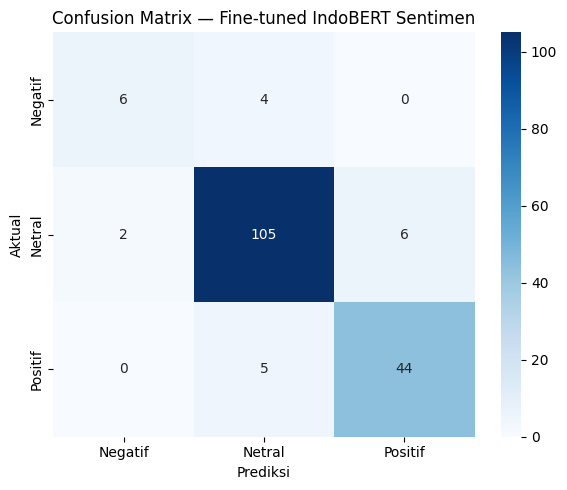

In [8]:
pred_output = trainer.predict(val_tok)
y_pred = np.argmax(pred_output.predictions, axis=-1)
y_true = pred_output.label_ids

print('=== Classification Report ===')
report = classification_report(
    y_true, y_pred,
    target_names=['Negatif', 'Netral', 'Positif'],
    digits=4
)
print(report)

# Simpan sebagai tabel untuk tesis
report_dict = classification_report(
    y_true, y_pred, target_names=['Negatif','Netral','Positif'],
    digits=4, output_dict=True
)
df_report = pd.DataFrame(report_dict).transpose()
df_report.to_csv('tabel_evaluasi_indobert.csv')
print('Tabel evaluasi disimpan: tabel_evaluasi_indobert.csv')

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Negatif','Netral','Positif'],
            yticklabels=['Negatif','Netral','Positif'], ax=ax)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Aktual')
ax.set_title('Confusion Matrix — Fine-tuned IndoBERT Sentimen')
plt.tight_layout()
plt.savefig('confusion_matrix_indobert.png', dpi=200)
plt.show()


---
## 💾 CELL 9 — Simpan Model Fine-tuned

Model ini nanti dipakai untuk klasifikasi seluruh 4.131 artikel (bukan cuma 859 yang berlabel).

In [9]:
SAVE_PATH = './indobert_sentimen_finetuned'
trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)
print(f'✅ Model disimpan di: {SAVE_PATH}')

# Opsional: kompres untuk didownload dari Colab
!zip -r indobert_sentimen_finetuned.zip {SAVE_PATH}
print('✅ Siap didownload: indobert_sentimen_finetuned.zip')


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model disimpan di: ./indobert_sentimen_finetuned
✅ Siap didownload: indobert_sentimen_finetuned.zip


'zip' is not recognized as an internal or external command,
operable program or batch file.


---
## 🧪 CELL 10 — Uji Coba Inferensi (Sanity Check)

In [10]:
from transformers import pipeline

classifier = pipeline(
    'text-classification',
    model=SAVE_PATH,
    tokenizer=SAVE_PATH,
    device=0 if torch.cuda.is_available() else -1
)

contoh_teks = [
    'Laba ADRO Naik Tajam, Investor Optimis Prospek Batu Bara Membaik',
    'PGN Umumkan Kerja Sama Baru dengan Mitra Strategis',
    'Harga Batu Bara Anjlok, Saham ITMG Terjun Bebas ke Level Terendah',
]

for teks in contoh_teks:
    hasil = classifier(teks)[0]
    print(f'[{hasil["label"]:8s} | {hasil["score"]:.3f}]  {teks}')


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[Positif  | 0.991]  Laba ADRO Naik Tajam, Investor Optimis Prospek Batu Bara Membaik
[Netral   | 0.995]  PGN Umumkan Kerja Sama Baru dengan Mitra Strategis
[Negatif  | 0.994]  Harga Batu Bara Anjlok, Saham ITMG Terjun Bebas ke Level Terendah


---
## 📌 LANGKAH SELANJUTNYA

1. Download `indobert_sentimen_finetuned.zip` dari Colab
2. Jalankan model ini untuk klasifikasi **seluruh 4.131 artikel** di `berita_gabungan_clean.csv`
3. Konversi label → skor numerik (Positif +1, Netral 0, Negatif -1) sesuai Tabel 3.4 proposal
4. **Agregasi skor harian** per `Tanggal` + `Kode_Emiten`
5. Baru masuk **Langkah 1 EDA: Statistik Deskriptif Skor Sentimen** (yang kita rencanakan di awal)
6. Merge dengan dataset teknikal (`Volatilitas`, `RSI`, `MA_5`, dll) → lanjut ke pemodelan XGBoost & LSTM